# Early-Warning Fall Prediction for Humanoid / Assistive Robotics
### A Cost-Sensitive, Time-to-Impact Trade-off Analysis on the UMAFall dataset
**Course:** Pattern Recognition & Machine Learning (PRML)

**Core question.** A system that reports a fall *after* the person is on the floor is useless for protection.
How **early** (lead time before impact) can a wearable-sensor classifier raise an alarm, and what does asking for
more lead time cost us in **missed falls** and **false alarms**?

**What this notebook does (in order)**
1. Load & parse every UMAFall CSV (5 body positions, accel + gyro interleaved in one file).
2. Put every sensor on a common 20 Hz time grid and locate the **impact instant** of each fall.
3. Slide a 1 s *causal* window over every trial and compute physics-motivated features (free-fall dip, jerk, tilt change, gyro, repetitiveness).
4. For each **lead time tau** (0 - 1.0 s before impact) build a *different* labelled problem: "will impact happen about tau seconds from now?"
5. Train classifiers with **subject-level** cross-validation (no person appears in both train and test).
6. Choose the alarm threshold by **expected cost** (a missed fall costs C_FN, a false alarm costs C_FP) - selected on *training data only* (nested).
7. Report window-level **and** trial-level (what a real system would experience) metrics, the recall-vs-false-alarm trade-off, cost-ratio sweeps, sensor-position comparison and error analysis.

> **How to run:** keep the CSVs anywhere under `./data` (the notebook finds them automatically) and use *Run All*. Override with `export UMAFALL_DIR=/path/to/folder` if needed.
> First run parses ~746 CSVs (1-3 min) and caches them; later runs are fast. Set `FAST=1` for a quick dry run.

## 0. Setup & configuration

In [1]:
import os, re, glob, time, warnings, pickle
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
if os.environ.get("MPL_BACKEND"): matplotlib.use(os.environ["MPL_BACKEND"])
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from scipy.ndimage import uniform_filter1d
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- CONFIG (edit here) -----------------------------
def find_data_dir():
    # Use UMAFALL_DIR if set, else look inside ./data (any depth) for the folder that holds the UMAFall_*.csv files.
    for base in [os.environ.get("UMAFALL_DIR"), "data/UMAFall", "data", "."]:
        if base and Path(base).exists():
            hit = next(Path(base).rglob("UMAFall_Subject_*.csv"), None)
            if hit is not None: return hit.parent
    return Path("data/UMAFall")
DATA_DIR = find_data_dir()
OUT_DIR  = Path(os.environ.get("OUT_DIR", "results")); OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE    = OUT_DIR / "trials_cache.pkl"
FAST     = os.environ.get("FAST", "0") == "1"      # quick dry-run mode

FS      = 20.0          # common sampling rate (Hz) - SensorTags run at ~20 Hz
WIN     = 20            # decision window = 1.0 s
CTX     = 40            # context used for 'repetitiveness' features = 2.0 s
POS_WIDTH = 0.30        # positives = windows ending within 0.3 s around (t_impact - tau)
AMBIG_BEFORE = 2.0      # fall-trial windows ending 2 s+ before impact are 'normal' negatives; the gap is dropped as ambiguous
LEADS   = [0.0, 0.3, 0.6] if FAST else [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]
MAIN_POS = "CHEST"      # main sensor position (see Section 9 for all positions)
C_FN, C_FP = 10.0, 1.0  # a missed fall is 10x worse than a false alarm (swept in Section 8)
N_SPLITS, N_INNER = (3, 2) if FAST else (5, 3)
SEED = 42
POS = {0: "RIGHTPOCKET", 1: "CHEST", 2: "WAIST", 3: "WRIST", 4: "ANKLE"}
STYPE = {0: "acc", 1: "gyr", 2: "mag"}
print("DATA_DIR :", DATA_DIR.resolve(), "| CSV files:", len(list(DATA_DIR.glob("UMAFall_Subject_*.csv"))))
print("FAST mode:", FAST, "| lead times (s):", LEADS)

DATA_DIR : /workspace/prml/fall_prediction/data/UMAFall | CSV files: 746
FAST mode: False | lead times (s): [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]


## 1. Loading the data
**File format (from the dataset description).** ~40 `%` metadata lines, then rows
`TimeStamp; Sample No; X; Y; Z; Sensor Type; Sensor ID`. All 5 positions x 3 sensor types are *interleaved*, so we split by `(Sensor ID, Sensor Type)`.
Accelerometer in g, gyroscope in deg/s. We ignore the magnetometer (only useful for orientation estimation).

**Two real-data quirks we handle explicitly (we saw both in the sample files):**
* The **phone (RIGHTPOCKET)** records only the accelerometer, at **~200 Hz**, while the **SensorTags** record acc+gyro+mag at **~20 Hz**. We low-pass (block-average) the phone and resample it to 20 Hz.
* The `TimeStamp` column is coarse (repeats for 2-3 rows), so we fit a straight line *timestamp ~ sample index* per stream to get clean, evenly-spaced times, and align all streams of a trial on the same clock.
* Some trials lack a sensor (e.g. no ankle tag) -> we never assume all 5 positions exist.

In [2]:
NAME_RE = re.compile(r"UMAFall_Subject_(\d+)_(ADL|Fall)_(.+?)_(\d+)_(\d{4}-\d\d-\d\d_\d\d-\d\d-\d\d)\.csv$")
COLS = ["t", "n", "x", "y", "z", "type", "sid"]

def load_trial(path):
    m = NAME_RE.match(Path(path).name)
    if m is None: return None
    subj, kind, act, trial, stamp = m.groups()
    df = pd.read_csv(path, sep=";", comment="%", header=None, usecols=range(7), names=COLS, on_bad_lines="skip")
    df = df.apply(pd.to_numeric, errors="coerce").dropna()
    streams = {}
    for (sid, typ), g in df.groupby(["sid", "type"]):
        sid, typ = int(sid), int(typ)
        if typ == 2 or sid not in POS or len(g) < 2 * WIN: continue       # skip magnetometer / junk
        g = g.sort_values("n", kind="mergesort")
        idx = np.arange(len(g)); ts = g["t"].values / 1000.0
        slope, icpt = np.polyfit(idx, ts, 1)                               # clean, evenly spaced time axis
        if slope <= 0: continue
        t = icpt + slope * idx; xyz = g[["x", "y", "z"]].values.astype(float)
        fs_est = 1.0 / slope
        if fs_est > 2 * FS:                                                # phone @200 Hz -> anti-alias then decimate
            xyz = uniform_filter1d(xyz, size=int(round(fs_est / FS)), axis=0, mode="nearest")
        streams[(POS[sid], STYPE[typ])] = (t, xyz)
    if not streams: return None
    t0 = min(s[0][0] for s in streams.values())
    T = float(np.median([s[0][-1] - t0 for s in streams.values()]))
    grid = np.arange(0, T, 1 / FS)
    acc, gyr = {}, {}
    for (pos, kindS), (t, xyz) in streams.items():
        arr = np.column_stack([np.interp(grid, t - t0, xyz[:, k]) for k in range(3)])
        (acc if kindS == "acc" else gyr)[pos] = arr
    rec = dict(name=Path(path).name, subject=int(subj), is_fall=int(kind == "Fall"), activity=act, trial=int(trial),
               N=len(grid), acc=acc, gyr=gyr, t_imp=np.nan, ref_pos=None)
    if rec["is_fall"]:                                                     # impact = peak SMV of the best available reference sensor
        for ref in ["CHEST", "WAIST", "RIGHTPOCKET", "WRIST", "ANKLE"]:
            if ref in acc:
                smv = np.linalg.norm(acc[ref], axis=1)
                rec["t_imp"], rec["ref_pos"], rec["peak_g"] = grid[int(np.argmax(smv))], ref, float(smv.max()); break
    return rec

files = sorted(glob.glob(str(DATA_DIR / "UMAFall_*.csv")))
print("CSV files found:", len(files))
assert len(files) > 0, "No CSV files found - check DATA_DIR (see run instructions PDF)."
if CACHE.exists() and os.environ.get("REBUILD") != "1":
    trials = pickle.load(open(CACHE, "rb")); print("loaded cache:", len(trials), "trials")
else:
    t0 = time.time()
    trials = [r for r in Parallel(n_jobs=-1)(delayed(load_trial)(f) for f in files) if r is not None]
    pickle.dump(trials, open(CACHE, "wb")); print(f"parsed {len(trials)} trials in {time.time()-t0:.0f}s (cached to {CACHE})")

CSV files found: 746
loaded cache: 746 trials


### 1.1 Sanity checks: what do we actually have?
Class balance, subjects, fall types, and **which sensors exist in which trials**. This table is worth quoting in the report: the dataset is *small* (a few hundred trials from ~19 people) and imbalanced, so subject-level evaluation matters.

In [3]:
meta = pd.DataFrame([{k: r[k] for k in ["name", "subject", "is_fall", "activity", "trial", "N", "t_imp"]} |
                     {"peak_g": r.get("peak_g", np.nan), **{f"has_{p}": (p in r["acc"]) for p in POS.values()}} for r in trials])
print("trials:", len(meta), "| falls:", int(meta.is_fall.sum()), "| ADL:", int((1-meta.is_fall).sum()), "| subjects:", meta.subject.nunique())
print("\nTrials per activity:\n", meta.groupby(["is_fall", "activity"]).size().to_string())
print("\nSensor availability (number of trials having that accelerometer):\n", meta[[c for c in meta if c.startswith('has_')]].sum().to_string())
print("\nTrial duration (s): mean %.1f, min %.1f, max %.1f" % (meta.N.mean()/FS, meta.N.min()/FS, meta.N.max()/FS))
print("\nFall impact time (s from start): mean %.2f, min %.2f, max %.2f" % (meta.t_imp.mean(), meta.t_imp.min(), meta.t_imp.max()))
print("Fall peak SMV (g): median %.2f | trials with peak < 1.5 g (suspicious): %d" % (meta.peak_g.median(), (meta.peak_g < 1.5).sum()))
print("\nFalls per subject:\n", meta[meta.is_fall == 1].groupby("subject").size().to_string())

trials: 746 | falls: 208 | ADL: 538 | subjects: 19

Trials per activity:
 is_fall  activity                 
0        Aplausing                    42
         Bending                      59
         GoDownstairs                 20
         GoUpstairs                   20
         HandsUp                      43
         Hopping                      53
         Jogging                      28
         LyingDown_OnABed             57
         MakingACall                  46
         OpeningDoor                  43
         Sitting_GettingUpOnAChair    64
         Walking                      63
1        backwardFall                 73
         forwardFall                  71
         lateralFall                  64

Sensor availability (number of trials having that accelerometer):
 has_RIGHTPOCKET    746
has_CHEST          745
has_WAIST          617
has_WRIST          746
has_ANKLE          643

Trial duration (s): mean 15.0, min 13.4, max 16.6

Fall impact time (s from start): mean 3.5

### 1.2 Look at the physics: free-fall dip -> impact spike (fall) vs. jogging (hard negative)
`SMV = sqrt(x^2+y^2+z^2)` is orientation-invariant. A fall shows **~1 g -> dip toward 0 g (free-fall) -> sharp spike -> stillness**.
Jogging can reach an *equal or larger* peak than a fall, which is exactly why a plain "peak > threshold" rule fails and why we need richer features.

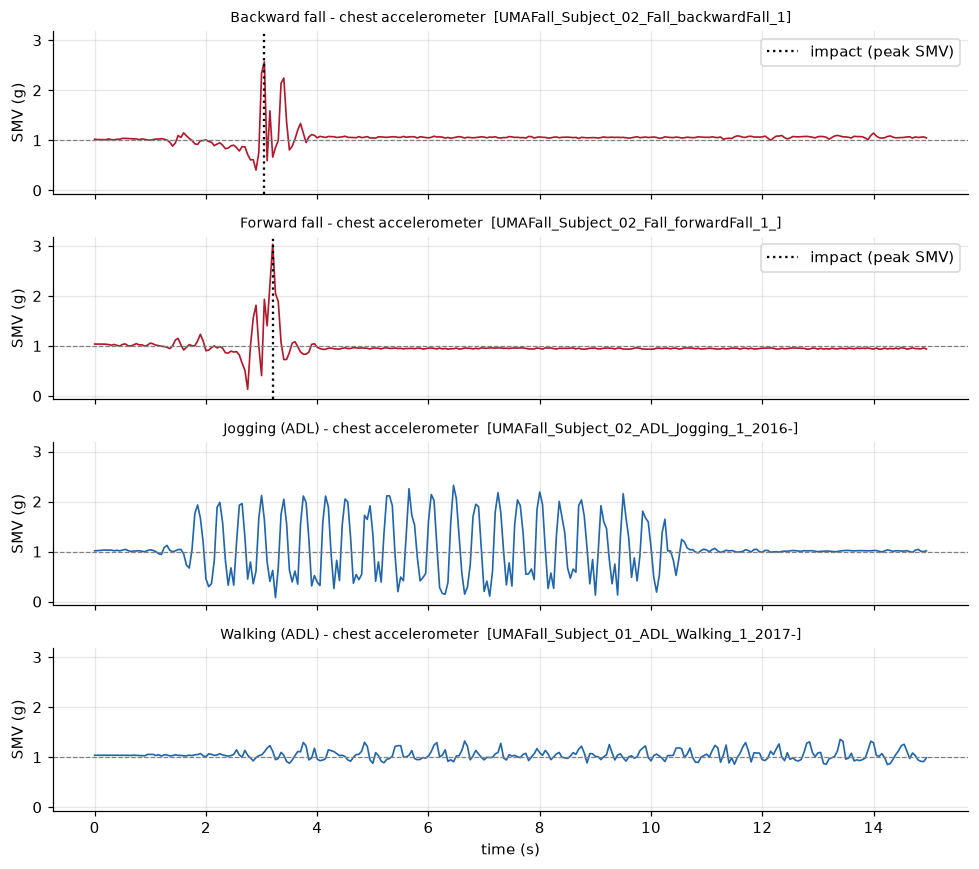

In [4]:
def smv_of(r, pos=MAIN_POS):
    return np.linalg.norm(r["acc"][pos], axis=1) if pos in r["acc"] else None
def first(pred):
    return next(r for r in trials if pred(r) and MAIN_POS in r["acc"])
ex = [("Backward fall", first(lambda r: r["is_fall"] and "backward" in r["activity"])),
      ("Forward fall",  first(lambda r: r["is_fall"] and "forward" in r["activity"])),
      ("Jogging (ADL)", first(lambda r: r["activity"] == "Jogging")),
      ("Walking (ADL)", first(lambda r: r["activity"] == "Walking"))]
fig, axs = plt.subplots(len(ex), 1, figsize=(9, 8), sharex=True, sharey=True)
for ax, (title, r) in zip(axs, ex):
    s = smv_of(r); ax.plot(np.arange(len(s)) / FS, s, lw=1.1, color="#b2182b" if r["is_fall"] else "#2166ac")
    ax.axhline(1, color="grey", ls="--", lw=.8)
    if r["is_fall"]: ax.axvline(r["t_imp"], color="k", ls=":", label="impact (peak SMV)"); ax.legend(loc="upper right")
    ax.set_ylabel("SMV (g)"); ax.set_title(f"{title} - chest accelerometer  [{r['name'][:38]}]", fontsize=9)
axs[-1].set_xlabel("time (s)"); plt.tight_layout(); plt.savefig(OUT_DIR / "fig01_signals.png", dpi=150); plt.show()

## 2. Windowing & feature engineering (strictly causal)
A decision at time *t* may only use data **up to t** (otherwise it isn't an early-warning system). We slide a **1 s window** (20 samples) ending at every sample
(every 0.05 s for falls, every 0.1 s for ADLs) and also look at a **2 s context** for repetitiveness.

| Group | Features | Why |
|---|---|---|
| Free-fall dip | `smv_min`, `smv_min_last05`, `frac_below_07`, `dip_depth` (previous mean - min), `smv_argmin_frac` | support force vanishes -> SMV -> 0 g *before* impact (this is the early-warning cue) |
| Magnitude / dynamics | `smv_mean/std/max/range/last`, `slope_last`, `jerk_max/mean` | sudden change of acceleration |
| Orientation | `tilt_change_deg` (angle between gravity direction at window start vs end) | body is tipping over |
| Rotation | `gyr_mean/max/std/last/slope`, `gyr_ctx_max` | loss of balance = fast rotation (not available for phone) |
| Repetitiveness | `ctx_std`, `ctx_peaks`, `ctx_mad`, `prev_std` | jogging/hopping/clapping are repetitive, a fall is a single isolated event |

> **Note:** *post-impact stillness* (std of SMV after the impact) is a great *detector* feature but is **impossible for early warning** because it lives in the future - an important point for the viva.

In [5]:
def extract(A, G=None):
    # A: (n, CTX, 3) accel windows (g); G: (n, CTX, 3) gyro windows or None. Returns dict of feature arrays.
    smv = np.linalg.norm(A, axis=2); w = smv[:, -WIN:]; d = np.diff(w, axis=1) * FS
    prev = smv[:, :-WIN]
    f = {}
    f["smv_mean"] = w.mean(1); f["smv_std"] = w.std(1); f["smv_min"] = w.min(1); f["smv_max"] = w.max(1)
    f["smv_range"] = f["smv_max"] - f["smv_min"]; f["smv_last"] = w[:, -1]
    f["smv_min_last05"] = w[:, -10:].min(1); f["smv_std_last05"] = w[:, -10:].std(1)
    f["smv_argmin_frac"] = w.argmin(1) / (WIN - 1)
    f["frac_below_07"] = (w < 0.7).mean(1); f["frac_above_15"] = (w > 1.5).mean(1)
    f["slope_last"] = (w[:, -1] - w[:, -6]) * FS / 5
    f["jerk_max"] = np.abs(d).max(1); f["jerk_mean"] = np.abs(d).mean(1)
    f["prev_mean"] = prev.mean(1); f["prev_std"] = prev.std(1); f["dip_depth"] = f["prev_mean"] - f["smv_min"]
    a1 = A[:, -WIN:-WIN + 5].mean(1); a2 = A[:, -5:].mean(1)
    cosang = (a1 * a2).sum(1) / (np.linalg.norm(a1, axis=1) * np.linalg.norm(a2, axis=1) + 1e-9)
    f["tilt_change_deg"] = np.degrees(np.arccos(np.clip(cosang, -1, 1)))
    f["ctx_std"] = smv.std(1); f["ctx_max"] = smv.max(1); f["ctx_mad"] = np.abs(smv - smv.mean(1, keepdims=True)).mean(1)
    mid = smv[:, 1:-1]; f["ctx_peaks"] = ((mid > smv[:, :-2]) & (mid >= smv[:, 2:]) & (mid > 1.5)).sum(1)
    if G is not None:
        g = np.linalg.norm(G, axis=2); gw = g[:, -WIN:]
        f["gyr_mean"] = gw.mean(1); f["gyr_max"] = gw.max(1); f["gyr_std"] = gw.std(1); f["gyr_last"] = gw[:, -1]
        f["gyr_slope"] = (gw[:, -1] - gw[:, -6]) * FS / 5; f["gyr_ctx_max"] = g.max(1)
    return f

def build_window_table(trials, pos, use_gyro=True):
    # One row per causal window. Returns (meta DataFrame, feature DataFrame).
    M, F = [], []
    for ti, r in enumerate(trials):
        if pos not in r["acc"] or (use_gyro and pos not in r["gyr"]): continue
        acc = r["acc"][pos]; N = len(acc)
        pad = lambda x: np.vstack([np.repeat(x[:1], CTX - 1, 0), x])
        stride = 1 if r["is_fall"] else 2
        ends = np.arange(WIN - 1, N, stride)
        A = sliding_window_view(pad(acc), CTX, axis=0).transpose(0, 2, 1)[ends]
        G = sliding_window_view(pad(r["gyr"][pos]), CTX, axis=0).transpose(0, 2, 1)[ends] if use_gyro else None
        F.append(pd.DataFrame(extract(A, G)))
        M.append(pd.DataFrame({"trial": ti, "subject": r["subject"], "is_fall": r["is_fall"], "activity": r["activity"],
                               "t_end": ends / FS, "t_imp": r["t_imp"], "dur": N / FS}))
    return pd.concat(M, ignore_index=True), pd.concat(F, ignore_index=True).astype(np.float32)

t0 = time.time()
Wm, Wf = build_window_table(trials, MAIN_POS, use_gyro=True)
FEATS = list(Wf.columns)
print(f"{MAIN_POS}: {len(Wm):,} windows x {len(FEATS)} features from {Wm.trial.nunique()} trials ({time.time()-t0:.0f}s)")
Wf.describe().T[["mean", "std", "min", "max"]].round(3).head(12)

CHEST: 133,957 windows x 28 features from 745 trials (1s)


,mean,std,min,max
smv_mean,1.021,0.222,0.000,5.380
smv_std,0.134,0.279,0.000,4.306
smv_min,0.845,0.311,0.000,4.021
smv_max,1.317,0.780,0.000,11.315
smv_range,0.472,0.953,0.000,11.142
smv_last,1.026,0.386,0.000,11.315
smv_min_last05,0.878,0.302,0.000,4.042
smv_std_last05,0.120,0.273,0.000,4.408
smv_argmin_frac,0.497,0.318,0.000,1.000
frac_below_07,0.070,0.195,0.000,1.000


## 3. Defining the early-warning task (the "time-to-impact" part)
Let `t_imp` be the impact instant. For a **lead time tau** we ask: *using only data up to time t, is the impact going to happen roughly tau seconds from now?*

* **Positive** window: fall trial, window **ends** in `[t_imp - tau - 0.3 s, t_imp - tau]`.  (tau = 0 means "the window ends on the impact" = classic fall *detection*.)
* **Negative** windows: every window of every ADL trial, plus the calm part of fall trials (ends more than 2 s before impact).
* **Dropped (ambiguous)**: fall-trial windows between those zones, and everything after `t_imp - tau` - the model is never trained on, or credited for, information that arrives too late.

Larger tau -> the model must recognise the fall **earlier**, when the body has only just started to lose balance -> harder. The whole project is about *how fast performance decays with tau* and what it costs.

In [6]:
def assign_labels(M, tau, pos_width=POS_WIDTH, ctx=AMBIG_BEFORE):
    lab = np.full(len(M), np.nan)
    f = M.is_fall.values == 1; te = M.t_end.values; ti = M.t_imp.values
    lab[~f] = 0
    lab[f & (te < ti - ctx)] = 0
    lab[f & (te <= ti - tau + 1e-9) & (te >= ti - tau - pos_width - 1e-9)] = 1
    return lab

rows = []
for tau in LEADS:
    l = assign_labels(Wm, tau); rows.append({"tau (s)": tau, "positives": int((l == 1).sum()), "negatives": int((l == 0).sum()),
                                           "ignored": int(np.isnan(l).sum()), "pos : neg": f"1 : {(l==0).sum()/max((l==1).sum(),1):.0f}"})
print(pd.DataFrame(rows).to_string(index=False))

 tau (s)  positives  negatives  ignored pos : neg
     0.0       1456      78545    53956    1 : 54
     0.1       1456      78545    53956    1 : 54
     0.2       1456      78545    53956    1 : 54
     0.3       1456      78545    53956    1 : 54
     0.4       1456      78545    53956    1 : 54
     0.5       1456      78545    53956    1 : 54
     0.6       1456      78545    53956    1 : 54
     0.8       1453      78545    53959    1 : 54
     1.0       1430      78545    53982    1 : 55


## 4. Why not just use a threshold? (baselines)
Single-feature **ROC-AUC** at tau = 0 (detection) and tau = 0.3 s (early warning). A rule like *"peak SMV > x g"* is the textbook baseline;
the **free-fall dip** rule (`-smv_min`) is the physically-motivated one. The boxplot shows jogging/hopping produce peaks as large as falls (hard negatives).

                         ROC-AUC        PR-AUC       
tau                          0.0    0.3    0.0    0.3
rule                                                 
-(#peaks in 2 s)           0.508  0.580  0.018  0.022
free-fall dip (-min SMV)   0.826  0.759  0.049  0.035
max gyro                   0.864  0.703  0.103  0.030
max jerk                   0.805  0.661  0.048  0.024
peak SMV (max)             0.652  0.479  0.034  0.016
tilt change                0.868  0.771  0.085  0.041


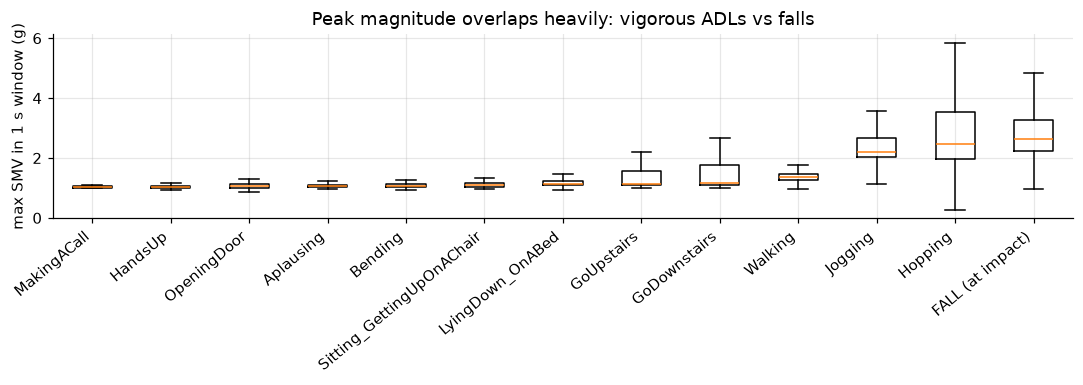

In [7]:
rows = []
for tau in [0.0, 0.3]:
    lab = assign_labels(Wm, tau); m = ~np.isnan(lab)
    for fe, sign, nm in [("smv_max", 1, "peak SMV (max)"), ("smv_min", -1, "free-fall dip (-min SMV)"), ("jerk_max", 1, "max jerk"),
                         ("tilt_change_deg", 1, "tilt change"), ("gyr_max", 1, "max gyro"), ("ctx_peaks", -1, "-(#peaks in 2 s)")]:
        rows.append({"tau": tau, "rule": nm, "ROC-AUC": roc_auc_score(lab[m], sign * Wf[fe].values[m]),
                     "PR-AUC": average_precision_score(lab[m], sign * Wf[fe].values[m])})
base = pd.DataFrame(rows); print(base.pivot(index="rule", columns="tau", values=["ROC-AUC", "PR-AUC"]).round(3))

fig, ax = plt.subplots(figsize=(10, 3.6))
tmp = Wm.assign(smv_max=Wf.smv_max.values)
tmp = tmp[(tmp.is_fall == 0) | ((tmp.t_end >= tmp.t_imp - 0.05) & (tmp.t_end <= tmp.t_imp + 0.05))]   # ADL windows vs fall-at-impact windows
tmp["group"] = np.where(tmp.is_fall == 1, "FALL (at impact)", tmp.activity)
order = tmp.groupby("group").smv_max.median().sort_values().index
ax.boxplot([tmp[tmp.group == g].smv_max for g in order], showfliers=False); ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order)
ax.set_ylabel("max SMV in 1 s window (g)"); ax.set_title("Peak magnitude overlaps heavily: vigorous ADLs vs falls")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.savefig(OUT_DIR / "fig02_peak_overlap.png", dpi=150); plt.show()

## 5. Models, subject-level CV and cost-sensitive thresholding
* **Subject-level splitting** (`StratifiedGroupKFold`, group = subject): a person's trials are *never* split between train and test - otherwise the model memorises individuals.
* Class imbalance (~1:50 or worse) handled with `class_weight`.
* **Cost-sensitive decision rule.** Predicting "fall" costs `C_FP` if wrong, staying silent costs `C_FN` if a fall was coming. For calibrated probabilities the Bayes-optimal threshold is `C_FP / (C_FP + C_FN)`.
  Because `class_weight` distorts probabilities, we instead **search the threshold that minimises total cost on the training folds** (inner CV out-of-fold scores) and apply it, untouched, to the held-out subjects. No test information leaks into the threshold.
* **Trial-level metrics** (closer to a deployed system): a fall counts as *caught early* if any alarm fires at least `tau` seconds before impact; ADL trials give a **false-alarm rate per minute** (alarms closer than 1 s are merged).

In [8]:
def make_rf():  return RandomForestClassifier(n_estimators=60 if FAST else 150, min_samples_leaf=5, max_samples=0.3,
                                              class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
def make_lr():  return make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, C=1.0))
def make_hgb(): return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.1, max_iter=150, class_weight="balanced", random_state=SEED)

def best_threshold(y, p, c_fn=C_FN, c_fp=C_FP):
    # threshold minimising  c_fn*FN + c_fp*FP  (flagging windows with p >= thr). Includes the 'never alarm' option.
    o = np.argsort(-p, kind="mergesort"); ys = y[o]; ps = p[o]
    tp = np.cumsum(ys); fp = np.cumsum(1 - ys); P = ys.sum()
    cost = c_fn * (P - tp) + c_fp * fp
    cost = np.where(np.r_[ps[:-1] > ps[1:], True], cost, np.inf)            # only cut where the score changes
    i = int(np.argmin(cost))
    if c_fn * P <= cost[i]: return float(ps[0] + 1e-6)
    return float((ps[i] + (ps[i + 1] if i + 1 < len(ps) else 0.0)) / 2)

def run_cv(Mx, X, tau, make_model, c_fn=C_FN, c_fp=C_FP, n_splits=N_SPLITS, n_inner=N_INNER, nested_threshold=True):
    # Subject-level CV. Returns out-of-fold probability for EVERY window of held-out subjects + the nested threshold used.
    lab = assign_labels(Mx, tau); idx = np.where(~np.isnan(lab))[0]; y = lab.astype(float)
    groups = Mx.subject.values; X = np.asarray(X)
    oof = np.full(len(Mx), np.nan); thr = np.full(len(Mx), np.nan)
    cv = StratifiedGroupKFold(n_splits, shuffle=True, random_state=SEED)
    for tr_i, te_i in cv.split(idx, y[idx], groups[idx]):
        tr = idx[tr_i]; model = make_model().fit(X[tr], y[tr])
        t = 0.5
        if nested_threshold:
            p_in = np.zeros(len(tr)); inner = StratifiedGroupKFold(n_inner, shuffle=True, random_state=SEED)
            for a, b in inner.split(tr, y[tr], groups[tr]):
                p_in[b] = make_model().fit(X[tr[a]], y[tr[a]]).predict_proba(X[tr[b]])[:, 1]
            t = best_threshold(y[tr], p_in, c_fn, c_fp)
        te_all = np.where(np.isin(groups, np.unique(groups[idx[te_i]])))[0]  # ALL windows of the held-out subjects
        oof[te_all] = model.predict_proba(X[te_all])[:, 1]; thr[te_all] = t
    return lab, oof, thr

# ---- trial-level evaluation helpers -------------------------------------------------------------
def trial_index(Mx):
    return {t: np.where(Mx.trial.values == t)[0] for t in Mx.trial.unique()}

def trial_metrics(Mx, tidx, oof, thr, tau, refractory=1.0):
    # Fall caught early: any alarm with window-end <= t_imp - tau. ADL: alarm events (merged within 1 s) per minute.
    caught, leads, fall_rows = [], [], []
    ev, minutes, adl_alarm_trials, n_adl = 0, 0.0, 0, 0
    thr = np.broadcast_to(thr, oof.shape)
    for t, ix in tidx.items():
        if np.isnan(oof[ix]).any(): continue
        te = Mx.t_end.values[ix]; flag = oof[ix] >= thr[ix]
        if Mx.is_fall.values[ix[0]] == 1:
            ti = Mx.t_imp.values[ix[0]]; ok = flag & (te <= ti - tau + 1e-9)
            caught.append(bool(ok.any())); leads.append(ti - te[ok].min() if ok.any() else np.nan)
            fall_rows.append((t, Mx.activity.values[ix[0]], bool(ok.any())))
        else:
            tt = te[flag]; n = 0; last = -9e9
            for x in tt:
                if x - last > refractory: n += 1
                last = x
            ev += n; minutes += Mx.dur.values[ix[0]] / 60; adl_alarm_trials += int(n > 0); n_adl += 1
    leads = np.array(leads, float)
    return {"fall_recall_trial": float(np.mean(caught)) if caught else np.nan,
            "median_lead_s": float(np.nanmedian(leads)) if np.isfinite(leads).any() else np.nan,
            "adl_alarms_per_min": ev / max(minutes, 1e-9), "adl_trials_with_alarm": adl_alarm_trials / max(n_adl, 1),
            "n_falls": len(caught), "n_adl": n_adl}, fall_rows, leads

def window_metrics(lab, oof, thr, c_fn=C_FN, c_fp=C_FP):
    m = ~np.isnan(lab) & ~np.isnan(oof); y = lab[m].astype(int); p = oof[m]; pred = p >= thr[m]
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum()); fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p), "recall": tp / max(tp + fn, 1),
            "precision": tp / max(tp + fp, 1), "FP": fp, "FN": fn, "cost": c_fn * fn + c_fp * fp}

### 5.1 Main experiment: Random Forest at every lead time (chest sensor, nested cost-optimal threshold)

In [9]:
tidx = trial_index(Wm); RES, STORE = [], {}
t0 = time.time()
for tau in LEADS:
    lab, oof, thr = run_cv(Wm, Wf.values, tau, make_rf)
    wm = window_metrics(lab, oof, thr); tm, fall_rows, leads = trial_metrics(Wm, tidx, oof, thr, tau)
    RES.append({"tau": tau, **wm, **tm}); STORE[tau] = dict(lab=lab, oof=oof, thr=thr, fall_rows=fall_rows, leads=leads)
    print(f"tau={tau:.1f}s  ROC-AUC={wm['roc_auc']:.3f}  PR-AUC={wm['pr_auc']:.3f}  | trial recall={tm['fall_recall_trial']:.2f} "
          f"median lead={tm['median_lead_s']:.2f}s  ADL false alarms/min={tm['adl_alarms_per_min']:.2f}   [{time.time()-t0:.0f}s]")
res = pd.DataFrame(RES); res.to_csv(OUT_DIR / "table_main_results.csv", index=False)
res.round(3)

tau=0.0s  ROC-AUC=0.987  PR-AUC=0.897  | trial recall=0.99 median lead=0.45s  ADL false alarms/min=1.10   [12s]
tau=0.1s  ROC-AUC=0.978  PR-AUC=0.855  | trial recall=0.97 median lead=0.55s  ADL false alarms/min=1.49   [24s]
tau=0.2s  ROC-AUC=0.975  PR-AUC=0.791  | trial recall=0.96 median lead=0.65s  ADL false alarms/min=2.12   [35s]
tau=0.3s  ROC-AUC=0.968  PR-AUC=0.722  | trial recall=0.94 median lead=0.75s  ADL false alarms/min=2.76   [46s]
tau=0.4s  ROC-AUC=0.959  PR-AUC=0.610  | trial recall=0.95 median lead=0.85s  ADL false alarms/min=3.74   [58s]
tau=0.5s  ROC-AUC=0.940  PR-AUC=0.479  | trial recall=0.94 median lead=1.03s  ADL false alarms/min=4.75   [70s]
tau=0.6s  ROC-AUC=0.914  PR-AUC=0.328  | trial recall=0.92 median lead=1.15s  ADL false alarms/min=5.05   [82s]
tau=0.8s  ROC-AUC=0.866  PR-AUC=0.169  | trial recall=0.82 median lead=1.50s  ADL false alarms/min=5.03   [94s]
tau=1.0s  ROC-AUC=0.836  PR-AUC=0.111  | trial recall=0.64 median lead=1.55s  ADL false alarms/min=4.14 

,tau,roc_auc,pr_auc,recall,precision,FP,FN,cost,fall_recall_trial,median_lead_s,adl_alarms_per_min,adl_trials_with_alarm,n_falls,n_adl
0,0.0,0.987,0.897,0.913,0.647,727,126,1987.0,0.990,0.450,1.105,0.255,208,537
1,0.1,0.978,0.855,0.863,0.606,816,199,2806.0,0.966,0.550,1.485,0.326,208,537
2,0.2,0.975,0.791,0.826,0.537,1037,253,3567.0,0.957,0.650,2.120,0.445,208,537
3,0.3,0.968,0.722,0.802,0.478,1276,288,4156.0,0.942,0.750,2.762,0.549,208,537
4,0.4,0.959,0.610,0.765,0.396,1699,342,5119.0,0.952,0.850,3.740,0.682,208,537
5,0.5,0.940,0.479,0.720,0.298,2474,407,6544.0,0.942,1.025,4.755,0.799,208,537
6,0.6,0.914,0.328,0.573,0.224,2881,622,9101.0,0.918,1.150,5.054,0.823,208,537
7,0.8,0.866,0.169,0.439,0.157,3423,815,11573.0,0.822,1.500,5.031,0.810,208,537
8,1.0,0.836,0.111,0.294,0.137,2636,1010,12736.0,0.639,1.550,4.135,0.678,208,537


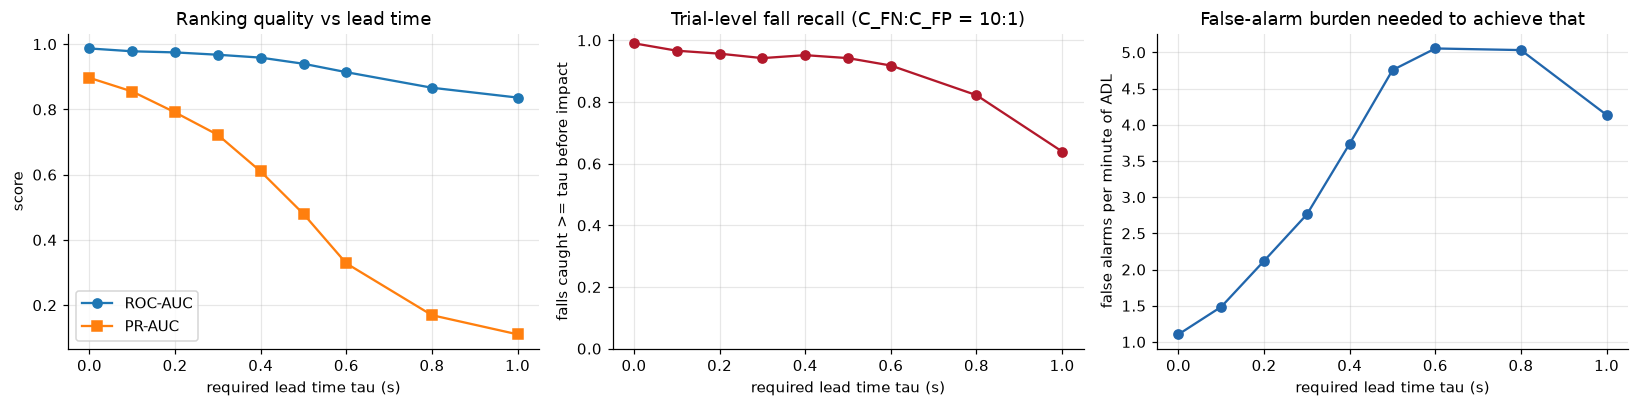

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].plot(res.tau, res.roc_auc, "o-", label="ROC-AUC"); axs[0].plot(res.tau, res.pr_auc, "s-", label="PR-AUC")
axs[0].set_xlabel("required lead time tau (s)"); axs[0].set_ylabel("score"); axs[0].set_title("Ranking quality vs lead time"); axs[0].legend()
axs[1].plot(res.tau, res.fall_recall_trial, "o-", color="#b2182b"); axs[1].set_ylim(0, 1.02)
axs[1].set_xlabel("required lead time tau (s)"); axs[1].set_ylabel("falls caught >= tau before impact"); axs[1].set_title(f"Trial-level fall recall (C_FN:C_FP = {C_FN:.0f}:{C_FP:.0f})")
axs[2].plot(res.tau, res.adl_alarms_per_min, "o-", color="#2166ac"); axs[2].set_xlabel("required lead time tau (s)")
axs[2].set_ylabel("false alarms per minute of ADL"); axs[2].set_title("False-alarm burden needed to achieve that")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig03_tau_tradeoff.png", dpi=150); plt.show()

### 5.2 The real trade-off: fall recall vs. false-alarm rate, for several lead times
Sweeping the alarm threshold on the out-of-fold scores traces an *operating curve* per `tau`. Curves shift down/right as `tau` grows: **earlier warning costs either missed falls or more false alarms**.

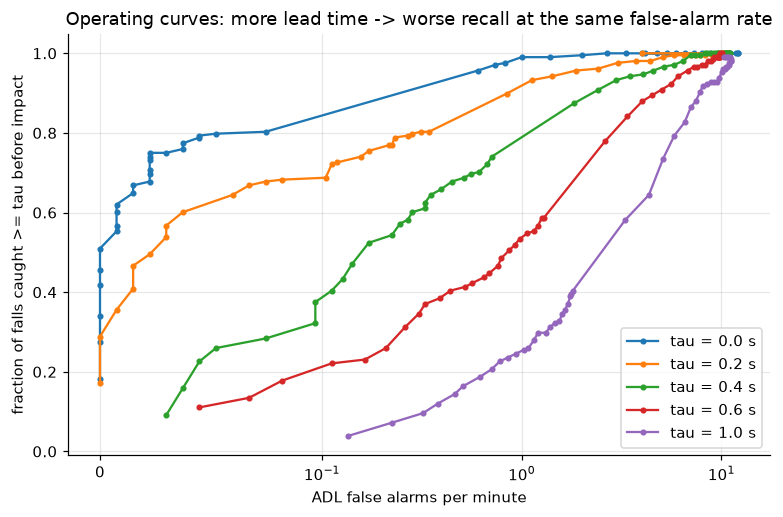

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))
sel = [t for t in [0.0, 0.2, 0.4, 0.6, 1.0] if t in STORE] or LEADS
for tau in sel:
    oof = STORE[tau]["oof"]; valid = oof[~np.isnan(oof)]
    thrs = np.unique(np.quantile(valid, np.r_[np.linspace(0.5, 0.99, 30), np.linspace(0.99, 0.9995, 25)]))
    pts = []
    for th in thrs:
        tm, _, _ = trial_metrics(Wm, tidx, oof, th, tau); pts.append((tm["adl_alarms_per_min"], tm["fall_recall_trial"]))
    pts = np.array(pts); ax.plot(pts[:, 0], pts[:, 1], "-o", ms=3, label=f"tau = {tau:.1f} s")
ax.set_xlabel("ADL false alarms per minute"); ax.set_ylabel("fraction of falls caught >= tau before impact"); ax.set_xscale("symlog", linthresh=0.1)
ax.set_title("Operating curves: more lead time -> worse recall at the same false-alarm rate"); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "fig04_operating_curves.png", dpi=150); plt.show()

## 6. Model comparison (at tau = 0.3 s, a realistic 'react before the floor' horizon)

In [12]:
TAU_REF = 0.3 if 0.3 in LEADS else LEADS[len(LEADS) // 2]
rows = []
for nm, mk in [("Logistic Regression", make_lr), ("Random Forest", make_rf), ("Hist. Gradient Boosting", make_hgb)]:
    lab, oof, thr = run_cv(Wm, Wf.values, TAU_REF, mk)
    wm = window_metrics(lab, oof, thr); tm, _, _ = trial_metrics(Wm, tidx, oof, thr, TAU_REF)
    rows.append({"model": nm, "ROC-AUC": wm["roc_auc"], "PR-AUC": wm["pr_auc"], "win recall": wm["recall"], "win precision": wm["precision"],
                 "expected cost": wm["cost"], "trial recall": tm["fall_recall_trial"], "ADL alarms/min": tm["adl_alarms_per_min"]})
    print(nm, "done")
cmp_df = pd.DataFrame(rows); cmp_df.to_csv(OUT_DIR / "table_model_comparison.csv", index=False)
print(f"\nTau = {TAU_REF} s"); cmp_df.round(3)

Logistic Regression done
Random Forest done
Hist. Gradient Boosting done

Tau = 0.3 s


,model,ROC-AUC,PR-AUC,win recall,win precision,expected cost,trial recall,ADL alarms/min
0,Logistic Regression,0.941,0.472,0.764,0.328,5714.0,0.947,3.695
1,Random Forest,0.968,0.722,0.802,0.478,4156.0,0.942,2.762
2,Hist. Gradient Boosting,0.960,0.710,0.832,0.376,4454.0,0.947,3.949


## 7. What does the model use? (feature importance, tau = 0.3 s)
Impurity importance of a Random Forest trained on all labelled windows (for *interpretation only* - the performance numbers above come from held-out subjects).

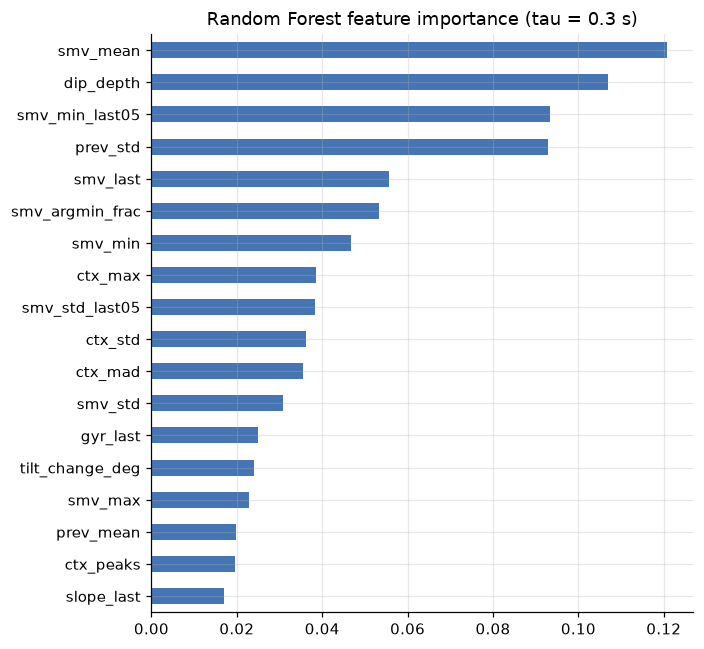

smv_mean           0.121
dip_depth          0.107
smv_min_last05     0.093
prev_std           0.093
smv_last           0.056
smv_argmin_frac    0.053
smv_min            0.047
ctx_max            0.039
dtype: float64

In [13]:
lab = assign_labels(Wm, TAU_REF); m = ~np.isnan(lab)
rf = make_rf().fit(Wf.values[m], lab[m])
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 6)); imp.tail(18).plot.barh(ax=ax, color="#4575b4")
ax.set_title(f"Random Forest feature importance (tau = {TAU_REF} s)"); plt.tight_layout(); plt.savefig(OUT_DIR / "fig05_feature_importance.png", dpi=150); plt.show()
imp.sort_values(ascending=False).head(8).round(3)

## 8. Cost-sensitivity analysis
How should the system behave if missing a fall is 1x, 5x, 10x, 50x ... worse than a false alarm? For each cost ratio we pick the cost-optimal threshold on the out-of-fold scores and report the resulting
trial-level recall and false-alarm rate. (Here the threshold is tuned on the same OOF scores, so these numbers are for *analysis of the trade-off*, not an unbiased test estimate - the unbiased nested numbers are in 5.1.)

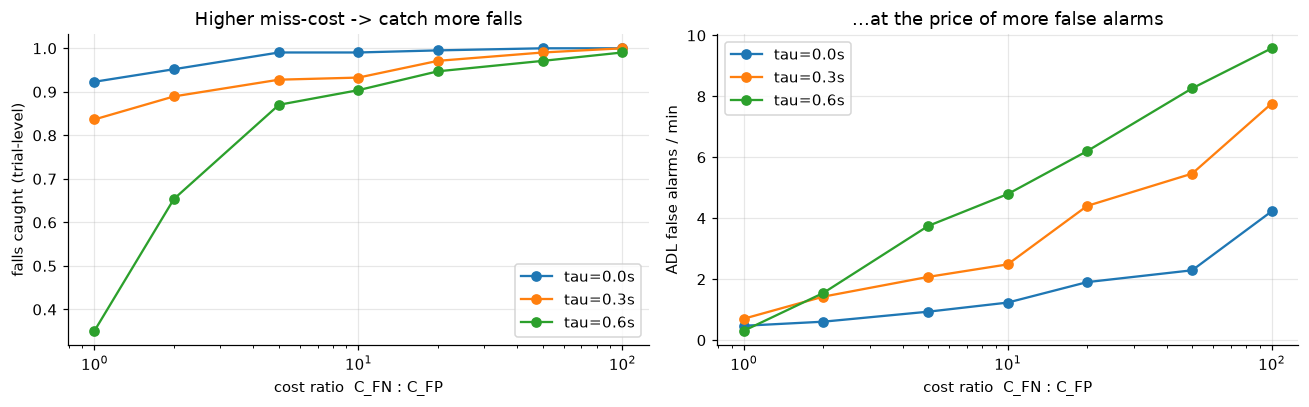

,tau,C_FN:C_FP,threshold,trial recall,ADL alarms/min,ADL trials w/ alarm
0,0.0,1,0.553,0.923,0.470,0.114
1,0.0,2,0.486,0.952,0.605,0.145
2,0.0,5,0.305,0.990,0.933,0.220
3,0.0,10,0.218,0.990,1.232,0.279
4,0.0,20,0.140,0.995,1.903,0.391
5,0.0,50,0.109,1.000,2.292,0.441
6,0.0,100,0.049,1.000,4.225,0.635
7,0.3,1,0.616,0.837,0.702,0.168
8,0.3,2,0.406,0.889,1.426,0.324
9,0.3,5,0.283,0.928,2.075,0.453


In [14]:
RATIOS = [1, 2, 5, 10, 20, 50, 100]; TAUS_C = [t for t in [0.0, 0.3, 0.6] if t in STORE]; rows = []
for tau in TAUS_C:
    S = STORE[tau]; lab, oof = S["lab"], S["oof"]; m = ~np.isnan(lab) & ~np.isnan(oof)
    for r_ in RATIOS:
        th = best_threshold(lab[m].astype(float), oof[m], c_fn=r_, c_fp=1.0)
        tm, _, _ = trial_metrics(Wm, tidx, oof, th, tau)
        rows.append({"tau": tau, "C_FN:C_FP": r_, "threshold": th, "trial recall": tm["fall_recall_trial"], "ADL alarms/min": tm["adl_alarms_per_min"], "ADL trials w/ alarm": tm["adl_trials_with_alarm"]})
cost_df = pd.DataFrame(rows); cost_df.to_csv(OUT_DIR / "table_cost_sweep.csv", index=False)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for tau in TAUS_C:
    d = cost_df[cost_df.tau == tau]
    axs[0].plot(d["C_FN:C_FP"], d["trial recall"], "o-", label=f"tau={tau:.1f}s"); axs[1].plot(d["C_FN:C_FP"], d["ADL alarms/min"], "o-", label=f"tau={tau:.1f}s")
for a, yl in zip(axs, ["falls caught (trial-level)", "ADL false alarms / min"]): a.set_xscale("log"); a.set_xlabel("cost ratio  C_FN : C_FP"); a.set_ylabel(yl); a.legend()
axs[0].set_title("Higher miss-cost -> catch more falls"); axs[1].set_title("...at the price of more false alarms")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig06_cost_sweep.png", dpi=150); plt.show()
cost_df.round(3)

## 9. Which sensor position? (accelerometer-only features, tau = 0.3 s)
The phone has **no gyroscope**, so for a fair comparison all five positions use the *accelerometer-only* feature set. Trials missing a position are skipped for that position (count shown).

RIGHTPOCKET done
CHEST done
WAIST done
WRIST done
ANKLE done


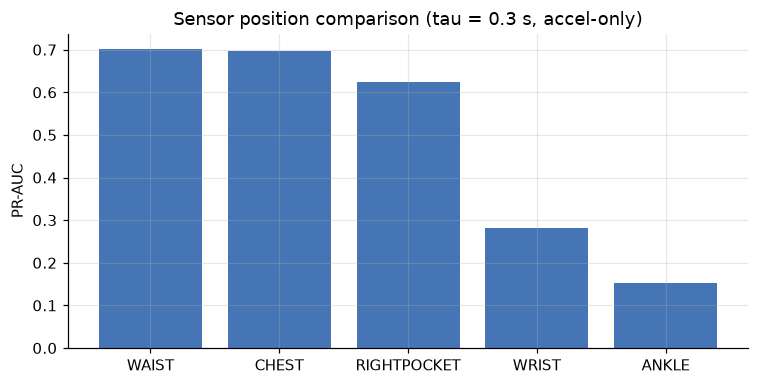

,position,trials used,ROC-AUC,PR-AUC,trial recall,ADL alarms/min
2,WAIST,617,0.974,0.701,0.989,3.178
1,CHEST,745,0.966,0.698,0.933,2.851
0,RIGHTPOCKET,746,0.970,0.623,0.971,3.740
3,WRIST,746,0.911,0.282,0.904,6.049
4,ANKLE,643,0.904,0.152,0.847,4.602


In [15]:
rows = []
for pos in POS.values():
    Mp, Fp = build_window_table(trials, pos, use_gyro=False)
    if len(Mp) == 0 or Mp.is_fall.sum() == 0: print("skip", pos); continue
    tix = trial_index(Mp); lab, oof, thr = run_cv(Mp, Fp.values, TAU_REF, make_rf)
    wm = window_metrics(lab, oof, thr); tm, _, _ = trial_metrics(Mp, tix, oof, thr, TAU_REF)
    rows.append({"position": pos, "trials used": Mp.trial.nunique(), "ROC-AUC": wm["roc_auc"], "PR-AUC": wm["pr_auc"],
                 "trial recall": tm["fall_recall_trial"], "ADL alarms/min": tm["adl_alarms_per_min"]}); print(pos, "done")
pos_df = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False); pos_df.to_csv(OUT_DIR / "table_positions.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 3.6)); ax.bar(pos_df.position, pos_df["PR-AUC"], color="#4575b4"); ax.set_ylabel("PR-AUC"); ax.set_title(f"Sensor position comparison (tau = {TAU_REF} s, accel-only)")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig07_positions.png", dpi=150); plt.show()
pos_df.round(3)

## 10. Error analysis
Which fall types are missed, which ADLs trigger false alarms (the hard negatives), and how much warning time do we actually get?

Fall recall by fall type (tau = 0.3 s):
            recall  n_trials
fall_type                  
backward     0.96        73
forward      0.94        71
lateral      0.92        64

Fraction of ADL trials that raised >=1 false alarm, by activity:
                            frac_trials_with_alarm  n_trials
activity                                                   
Bending                                      0.97        59
LyingDown_OnABed                             0.81        57
Jogging                                      0.79        28
Hopping                                      0.77        53
Sitting_GettingUpOnAChair                    0.77        64
GoDownstairs                                 0.75        20
Aplausing                                    0.37        41
OpeningDoor                                  0.30        43
Walking                                      0.30        63
HandsUp                                      0.28        43
GoUpstairs                      

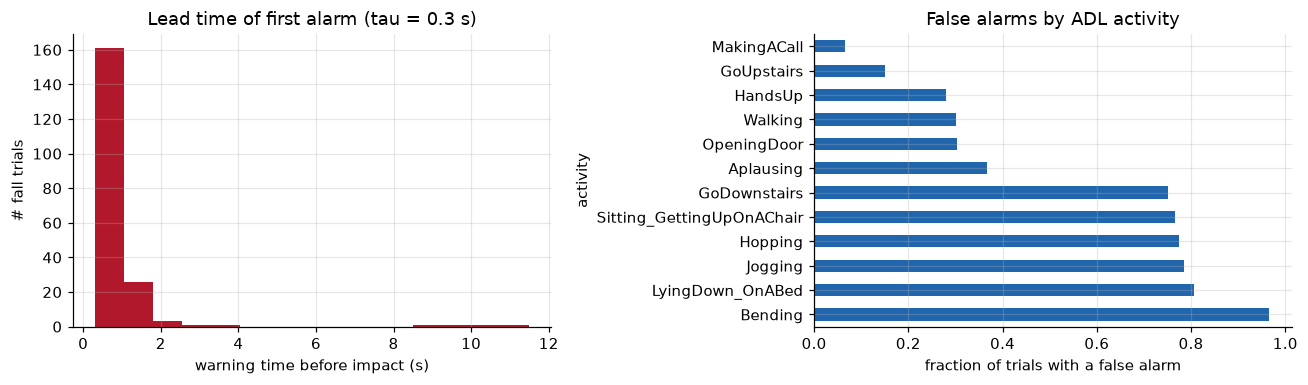

In [16]:
S = STORE[TAU_REF]; oof, thr = S["oof"], S["thr"]
fr = pd.DataFrame(S["fall_rows"], columns=["trial", "activity", "caught"])
fr["fall_type"] = fr.activity.str.replace("Fall", "", regex=False)
print(f"Fall recall by fall type (tau = {TAU_REF} s):\n", fr.groupby("fall_type").caught.agg(["mean", "count"]).round(2).rename(columns={"mean": "recall", "count": "n_trials"}).to_string())

adl_rows = []
for t, ix in tidx.items():
    if Wm.is_fall.values[ix[0]] == 1 or np.isnan(oof[ix]).any(): continue
    adl_rows.append((Wm.activity.values[ix[0]], bool((oof[ix] >= thr[ix]).any())))
adl_err = pd.DataFrame(adl_rows, columns=["activity", "false_alarm"]).groupby("activity").false_alarm.agg(["mean", "count"]).sort_values("mean", ascending=False)
print("\nFraction of ADL trials that raised >=1 false alarm, by activity:\n", adl_err.round(2).rename(columns={"mean": "frac_trials_with_alarm", "count": "n_trials"}).to_string())

leads = S["leads"][np.isfinite(S["leads"])]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].hist(leads, bins=15, color="#b2182b"); axs[0].set_xlabel("warning time before impact (s)"); axs[0].set_ylabel("# fall trials"); axs[0].set_title(f"Lead time of first alarm (tau = {TAU_REF} s)")
adl_err["mean"].plot.barh(ax=axs[1], color="#2166ac"); axs[1].set_xlabel("fraction of trials with a false alarm"); axs[1].set_title("False alarms by ADL activity")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig08_error_analysis.png", dpi=150); plt.show()

## 11. Summary table & discussion points

In [17]:
final = res[["tau", "roc_auc", "pr_auc", "fall_recall_trial", "median_lead_s", "adl_alarms_per_min", "adl_trials_with_alarm"]].round(3)
final.to_csv(OUT_DIR / "table_final_summary.csv", index=False); print(final.to_string(index=False))
r0, rx = res.iloc[0], res[res.tau == TAU_REF].iloc[0]
print(f"\nAuto-summary: as required lead time grows from 0 s to {TAU_REF} s, PR-AUC changes {r0.pr_auc:.2f} -> {rx.pr_auc:.2f} and trial-level fall recall "
      f"{r0.fall_recall_trial:.2f} -> {rx.fall_recall_trial:.2f} (ADL false alarms/min {r0.adl_alarms_per_min:.2f} -> {rx.adl_alarms_per_min:.2f}).")
print("All tables/figures saved in:", OUT_DIR.resolve())

 tau  roc_auc  pr_auc  fall_recall_trial  median_lead_s  adl_alarms_per_min  adl_trials_with_alarm
 0.0    0.987   0.897              0.990          0.450               1.105                  0.255
 0.1    0.978   0.855              0.966          0.550               1.485                  0.326
 0.2    0.975   0.791              0.957          0.650               2.120                  0.445
 0.3    0.968   0.722              0.942          0.750               2.762                  0.549
 0.4    0.959   0.610              0.952          0.850               3.740                  0.682
 0.5    0.940   0.479              0.942          1.025               4.755                  0.799
 0.6    0.914   0.328              0.918          1.150               5.054                  0.823
 0.8    0.866   0.169              0.822          1.500               5.031                  0.810
 1.0    0.836   0.111              0.639          1.550               4.135                  0.678

Auto-summ

### Discussion (use these for the report / viva)
* **Early warning is fundamentally harder than detection.** At tau = 0 the impact spike is inside the window; for tau > 0 the model only sees the *free-fall dip and tilt* that precede it. Performance decays with tau - the notebook quantifies by how much.
* **Cost-sensitivity changes the operating point, not the physics.** Raising `C_FN` lowers the threshold -> more falls caught but more false alarms (Sec. 8). The right ratio is application-dependent: an airbag hip-protector (cheap false alarm) vs. a robot that stops walking (expensive false alarm).
* **Hard negatives matter.** Jogging/hopping reach peaks as high as falls (Sec. 4), so a peak threshold is a weak baseline; repetitiveness (`ctx_*`) and dip-depth features are what separate them.
* **Sensor position trade-off.** Chest/waist are closest to the centre of mass; wrist/ankle/pocket are more convenient (Sec. 9).
* **Subject-level evaluation** avoids optimistic leakage; with only ~19 subjects, confidence intervals are wide.
* **Limitations.** (1) Falls are *simulated* by young healthy volunteers on mats - elderly falls differ. (2) 20 Hz sampling limits resolution of the dip (50 ms). (3) Impact instant defined as peak SMV. (4) Only ~200 fall trials, so per-fall-type and per-position numbers are noisy. (5) Window-level cost is a proxy for real-world cost per alarm event.
* **Future work.** Orientation-corrected features with the magnetometer, 1-D CNN / LSTM on raw windows, sensor fusion across positions, personalised thresholds, calibrated probabilities, testing on other datasets (e.g. SisFall, MobiAct).

## 12. Extension (our methodological contribution): strict evaluation and temporal-persistence alarms
Section 5 has two weaknesses that we fix here.
1. **The trial-level metric was generous.** A fall counted as *caught* if any alarm fired before `t_imp - tau`, even a stray alarm long before the fall, and such early alarms were never counted as false alarms.
   The **strict metric** only credits alarms inside the *actionable zone* `[t_imp - 2 s, t_imp - tau]`, and every alarm in the calm part of a fall trial counts as a **false alarm** (false-alarm minutes = ADL time + calm time of fall trials).
2. **Window-by-window decisions chatter.** A single noisy window can trigger an alarm. We test **temporal persistence**: an alarm is raised only if the *average score of the last Delta seconds* exceeds the threshold (causal smoothing; Delta = 0 is the original rule).
   Thresholds are chosen on the out-of-fold scores of the **other folds** only (never on the fold being evaluated), with the same 10:1 cost.

In [18]:
def get_fold_ids(Mx, tau):
    # re-create the exact subject-level folds used in run_cv (deterministic: same labels, groups, seed)
    lab = assign_labels(Mx, tau); idx = np.where(~np.isnan(lab))[0]; y = lab.astype(float); g = Mx.subject.values
    fold = np.full(len(Mx), -1)
    for k, (tr_i, te_i) in enumerate(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED).split(idx, y[idx], g[idx])):
        fold[np.isin(g, np.unique(g[idx[te_i]]))] = k
    return fold

def smooth_causal(te, s, delta):
    # mean of the scores whose window-end time lies in (t - delta, t]  -> uses only the past
    if delta <= 0: return s
    cs = np.r_[0.0, np.cumsum(s)]; j = np.searchsorted(te, te - delta, side="right"); i = np.arange(len(s))
    return (cs[i + 1] - cs[j]) / (i + 1 - j)

def count_events(times, refractory=1.0):
    n, last = 0, -9e9
    for x in times:
        if x - last > refractory: n += 1
        last = x
    return n

def strict_metrics(Mx, tidx, s_all, thr_row, tau, zone=AMBIG_BEFORE):
    caught, leads, ev, minutes, adl_alarm, n_adl = [], [], 0, 0.0, 0, 0
    for t, ix in tidx.items():
        if np.isnan(s_all[ix]).any(): continue
        te = Mx.t_end.values[ix]; flag = s_all[ix] >= thr_row[ix]
        if Mx.is_fall.values[ix[0]] == 1:
            ti = Mx.t_imp.values[ix[0]]
            ok = flag & (te >= ti - zone) & (te <= ti - tau + 1e-9)                 # actionable zone only
            caught.append(bool(ok.any())); leads.append(ti - te[ok].min() if ok.any() else np.nan)
            ev += count_events(te[flag & (te < ti - zone)]); minutes += max(ti - zone, 0) / 60   # early alarms = false alarms
        else:
            n = count_events(te[flag]); ev += n; minutes += Mx.dur.values[ix[0]] / 60
            adl_alarm += int(n > 0); n_adl += 1
    leads = np.array(leads, float)
    return {"strict_recall": float(np.mean(caught)), "median_lead_s": float(np.nanmedian(leads)) if np.isfinite(leads).any() else np.nan,
            "false_alarms_per_min": ev / max(minutes, 1e-9), "adl_trials_with_alarm": adl_alarm / max(n_adl, 1)}

DELTAS = [0.0, 0.2, 0.4]; EXT = []
for tau in [t for t in (0.0, 0.3, 0.6) if t in STORE]:
    lab, oof = STORE[tau]["lab"], STORE[tau]["oof"]; fold = get_fold_ids(Wm, tau)
    for delta in DELTAS:
        s_all = np.full(len(Wm), np.nan)
        for t, ix in tidx.items():
            if not np.isnan(oof[ix]).any(): s_all[ix] = smooth_causal(Wm.t_end.values[ix], oof[ix], delta)
        thr_row = np.full(len(Wm), np.nan)
        for k in range(N_SPLITS):
            tr = (fold != k) & (fold >= 0) & ~np.isnan(lab) & ~np.isnan(s_all)
            thr_row[fold == k] = best_threshold(lab[tr].astype(float), s_all[tr])
        EXT.append({"tau": tau, "smoothing_s": delta, **strict_metrics(Wm, tidx, s_all, thr_row, tau)})
ext_df = pd.DataFrame(EXT)
len_ = res[["tau", "fall_recall_trial", "adl_alarms_per_min"]].rename(columns={"fall_recall_trial": "lenient_recall (Sec.5)", "adl_alarms_per_min": "lenient_alarms/min (Sec.5)"})
ext_df = ext_df.merge(len_.assign(smoothing_s=0.0), on=["tau", "smoothing_s"], how="left")
ext_df.to_csv(OUT_DIR / "table_extension_strict_smoothing.csv", index=False); ext_df.round(3)

,tau,smoothing_s,strict_recall,median_lead_s,false_alarms_per_min,adl_trials_with_alarm,lenient_recall (Sec.5),lenient_alarms/min (Sec.5)
0,0.0,0.0,0.971,0.45,1.214,0.277,0.990,1.105
1,0.0,0.2,0.971,0.40,1.142,0.263,NaN,NaN
2,0.0,0.4,0.962,0.40,1.214,0.272,NaN,NaN
3,0.3,0.0,0.913,0.70,2.457,0.508,0.942,2.762
4,0.3,0.2,0.899,0.65,2.414,0.490,NaN,NaN
5,0.3,0.4,0.899,0.65,2.478,0.501,NaN,NaN
6,0.6,0.0,0.894,1.10,4.907,0.814,0.918,5.054
7,0.6,0.2,0.846,1.05,4.317,0.771,NaN,NaN
8,0.6,0.4,0.817,1.00,3.721,0.717,NaN,NaN


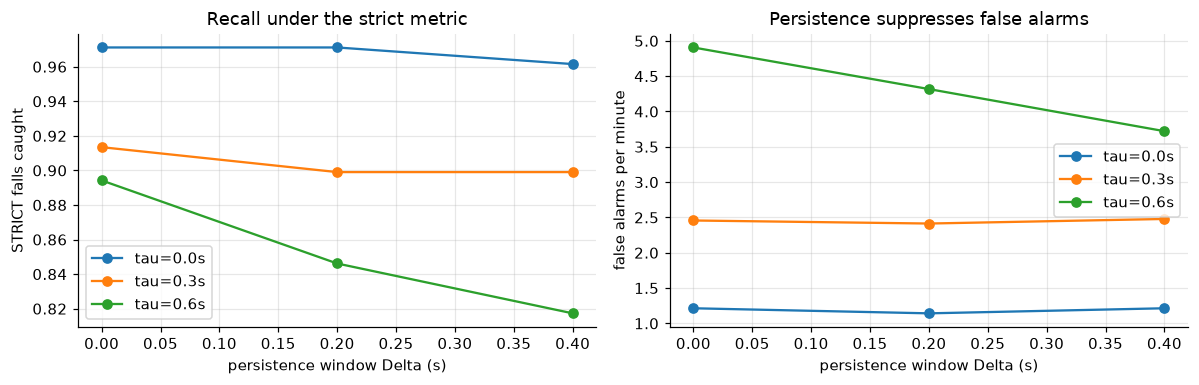

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for tau in ext_df.tau.unique():
    d = ext_df[ext_df.tau == tau]
    axs[0].plot(d.smoothing_s, d.strict_recall, "o-", label=f"tau={tau:.1f}s"); axs[1].plot(d.smoothing_s, d.false_alarms_per_min, "o-", label=f"tau={tau:.1f}s")
axs[0].set_ylabel("STRICT falls caught"); axs[1].set_ylabel("false alarms per minute")
for a in axs: a.set_xlabel("persistence window Delta (s)"); a.legend()
axs[0].set_title("Recall under the strict metric"); axs[1].set_title("Persistence suppresses false alarms")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig09_extension_persistence.png", dpi=150); plt.show()

## 13. Live demo: streaming early warning on any single trial
`demo_trial("<part of a file name>")` trains the random forest on **all other subjects**, picks the cost-optimal threshold from their out-of-fold scores, and replays the chosen trial window by window - exactly what a deployed system would see. It plots the chest signal, the model score, the threshold, the first alarm and (for falls) how many seconds *before the impact* the alarm fired.

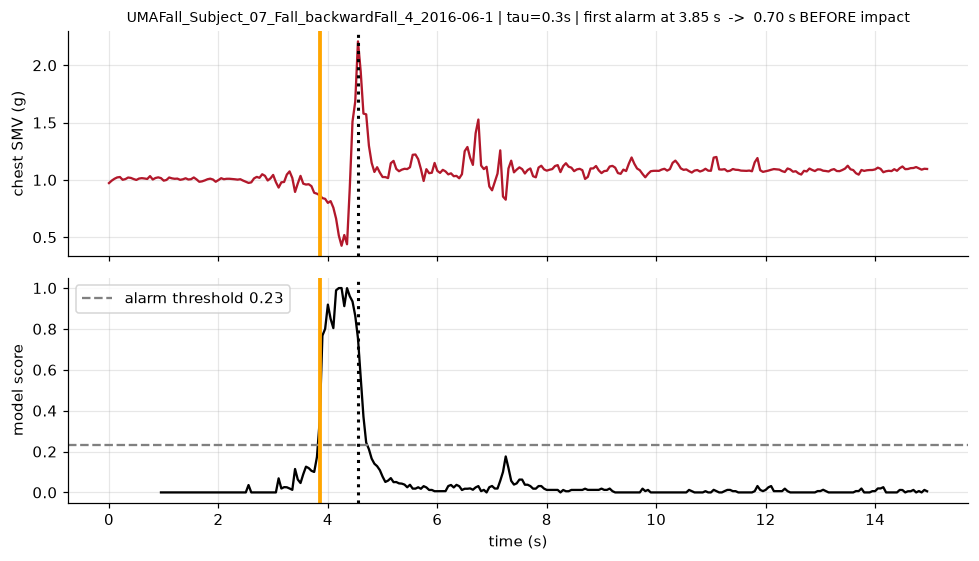

first alarm at 3.85 s  ->  0.70 s BEFORE impact


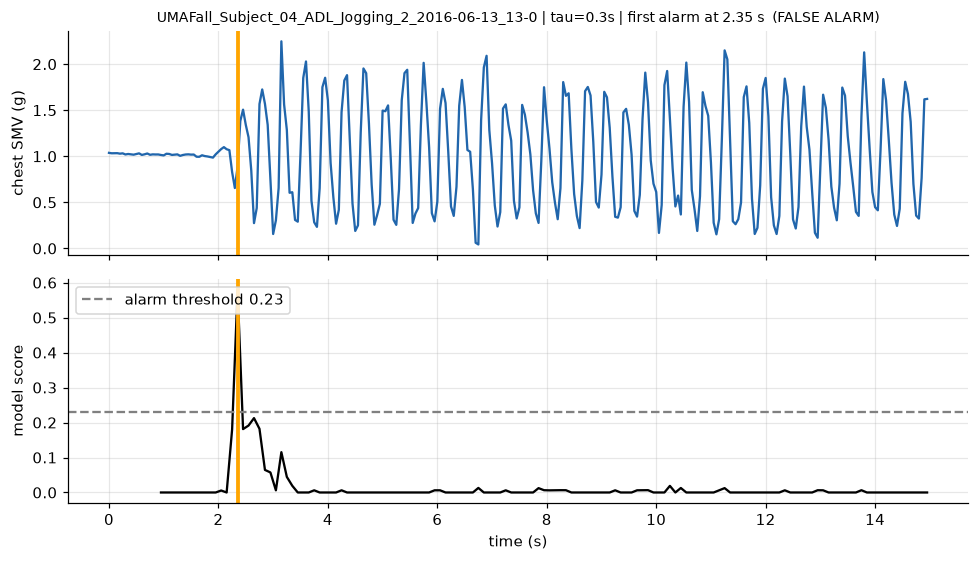

first alarm at 2.35 s  (FALSE ALARM)


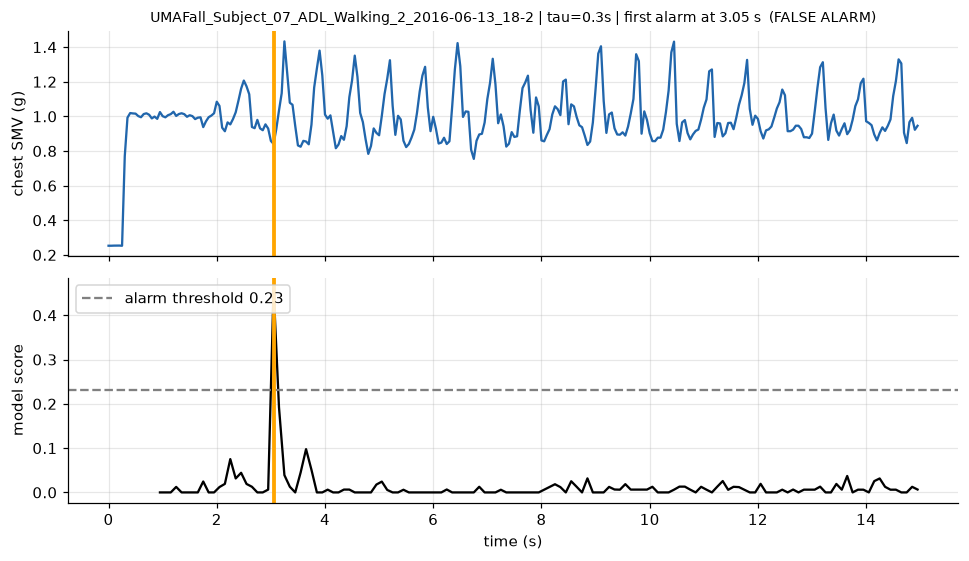

first alarm at 3.05 s  (FALSE ALARM)


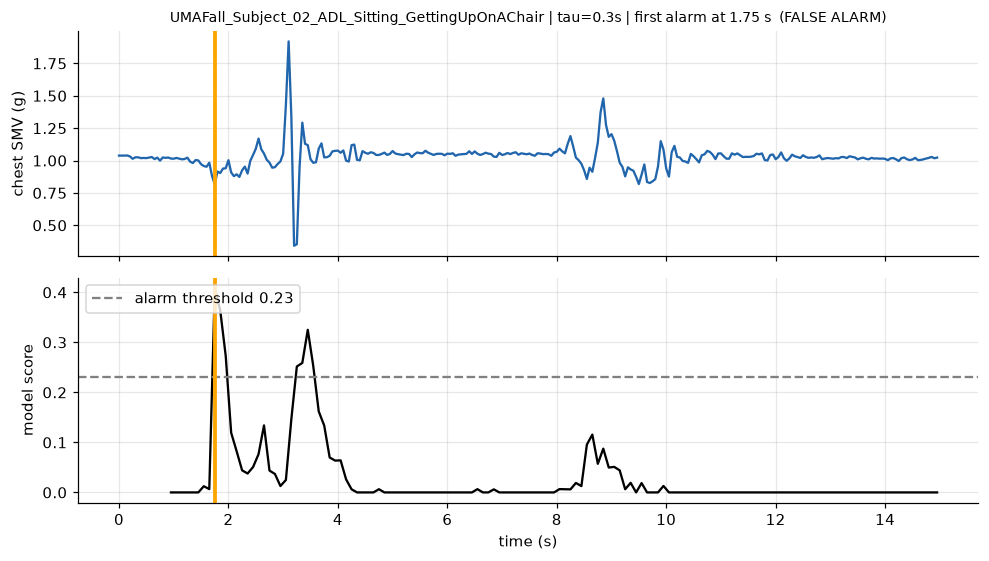

first alarm at 1.75 s  (FALSE ALARM)


In [20]:
def demo_trial(name_part, tau=0.3, delta=0.0):
    ti_ = next((i for i, r in enumerate(trials) if name_part in r["name"] and MAIN_POS in r["acc"]), None)
    if ti_ is None: print("trial not found:", name_part); return
    r = trials[ti_]; rows = np.where(Wm.trial.values == ti_)[0]; subj = r["subject"]
    lab, oof = STORE[tau]["lab"], STORE[tau]["oof"]; others = Wm.subject.values != subj
    ok = ~np.isnan(lab) & ~np.isnan(oof) & others
    thr = best_threshold(lab[ok].astype(float), oof[ok])                         # threshold from OTHER subjects only
    L = np.where(~np.isnan(lab) & others)[0]
    model = make_rf().fit(Wf.values[L], lab[L])                                  # trained without this person
    te = Wm.t_end.values[rows]; s = smooth_causal(te, model.predict_proba(Wf.values[rows])[:, 1], delta)
    alarm = np.where(s >= thr)[0]; smv = np.linalg.norm(r["acc"][MAIN_POS], axis=1)
    fig, ax = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
    ax[0].plot(np.arange(len(smv)) / FS, smv, color="#b2182b" if r["is_fall"] else "#2166ac"); ax[0].set_ylabel("chest SMV (g)")
    ax[1].plot(te, s, color="k"); ax[1].axhline(thr, ls="--", color="grey", label=f"alarm threshold {thr:.2f}"); ax[1].set_ylabel("model score"); ax[1].set_xlabel("time (s)")
    if r["is_fall"]:
        for a in ax: a.axvline(r["t_imp"], color="k", ls=":", lw=2)
    msg = "no alarm raised"
    if len(alarm):
        ta = te[alarm[0]]
        for a in ax: a.axvline(ta, color="orange", lw=2.5)
        msg = f"first alarm at {ta:.2f} s" + (f"  ->  {r['t_imp'] - ta:.2f} s BEFORE impact" if r["is_fall"] else "  (FALSE ALARM)")
    ax[0].set_title(f"{r['name'][:48]} | tau={tau}s | {msg}", fontsize=9); ax[1].legend(loc="upper left"); plt.tight_layout(); plt.show(); print(msg)

for nm in ["Subject_07_Fall_backwardFall_4", "Subject_04_ADL_Jogging_2", "Subject_07_ADL_Walking_2", "Subject_02_ADL_Sitting_GettingUpOnAChair_1"]:
    demo_trial(nm)